## Select the scene detector default threshold

**Q(τ)** = watermark bit accuracy (higher = better)

**T(τ)** = extract_time or reembed_frames ratio (lower = better)

**τ** = scene threshold (hyperparameter)

Increasing τ means:

- more re-embedding

- ↑ accuracy

- ↑ time cost

We want a **single τ that gives the best balance.**

This is a classic **two-objective optimization** problem:

- quality constraint (≥ target accuracy)

- knee/elbow method

- Pareto optimality (identify all optimal candidates)

#### c.f. environment:

Device

- GPU: 1X Tesla V100 GPU(VRAM: 32GB, 12.5 TFLOPS)
- CPU: Xeon® Gold 6130

Dataset

- SA V validation dataset(select 30, seed 42)

more details, please see the output/*_threshold_exp.log

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%cd ../../

## Content Detector

In [6]:
# -------------------------------------------------------------------
# analysis per threshold
# -------------------------------------------------------------------
content_paths = {
    27: "output/step_size_eval/ContentDetector/threshold_27.0/combined_metrics.csv",
    32: "output/step_size_eval/ContentDetector/threshold_32.0/combined_metrics.csv",
    37: "output/step_size_eval/ContentDetector/threshold_37.0/combined_metrics.csv",
    42: "output/step_size_eval/ContentDetector/threshold_42.0/combined_metrics.csv",
}

def compute_metrics_per_threshold(paths_dict: dict):
    content_dfs = {threshold: pd.read_csv(path) for threshold, path in paths_dict.items()}

    # -------------------------------------------------------------------
    # Compute metrics per threshold
    # -------------------------------------------------------------------
    results = []
    for threshold, df in content_dfs.items():
        embed_ratio = df["embed_ratio"].mean()  # total embeds / video frames (videoseal is 1 / step_size)
        acc = df["bit_acc_Identity_0"].mean()  # watermark quality
        embed_time = df["embed_time"].mean()
        pvalue = df["pvalue_Identity_0"].mean()
        log_pvalue = df["log_pvalue_Identity_0"].mean()
        capacity = df["capacity_Identity_0"].mean()
        extract_time = df["extract_time"].mean()
        
        results.append(dict(threshold=threshold, embed_ratio=embed_ratio, acc=acc, embed_time=embed_time, pvalue=pvalue, log_pvalue=log_pvalue, capacity=capacity, extract_time=extract_time))

    df = pd.DataFrame(results)
    return df

content_results_df = compute_metrics_per_threshold(content_paths)
content_results_df

,threshold,embed_ratio,acc,embed_time,pvalue,log_pvalue,capacity,extract_time
0,27,0.111982,0.962891,71.094608,1.869949e-06,64.552614,212.841200,0.937253
1,32,0.077161,0.955339,53.583549,6.253366e-08,62.324261,205.146391,0.424751
2,37,0.064779,0.949401,53.991348,7.112580e-06,60.962492,200.612675,0.432080
3,42,0.059981,0.946380,54.519285,4.277949e-07,59.986952,197.249860,0.437750


In [7]:
# -------------------------------------------------------------------
# Content Detector Compute metrics per (threshold, step_size)
# -------------------------------------------------------------------

def group_by_threshold_stepsize(paths_dict: dict):
    dfs = {}

    for threshold, path in paths_dict.items():
        df = pd.read_csv(path)
        df["threshold"] = threshold
        dfs[threshold] = df

    # Combine all into one big dataframe
    big_df = pd.concat(dfs.values(), ignore_index=True)

    # -------------------------------------------------------------------
    # Group by BOTH threshold and step_size
    # -------------------------------------------------------------------
    grouped = big_df.groupby(["threshold", "step_size"]).agg({
        "embed_ratio": "mean",
        "bit_acc_Identity_0": "mean",
        "embed_time": "mean",
        "pvalue_Identity_0": "mean",
        "log_pvalue_Identity_0": "mean",
        "capacity_Identity_0": "mean",
        "extract_time": "mean",
        "n_embed": "mean",
    })

    grouped = grouped.reset_index()
    return grouped

content_grouped = group_by_threshold_stepsize(content_paths)

content_grouped

,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
0,27,8,0.191876,0.999089,113.106360,9.846959e-75,76.511451,253.864217,2.515805,80.133333
1,27,16,0.123258,0.994922,80.208149,1.164406e-67,74.308853,245.866478,0.899017,52.066667
2,27,32,0.093775,0.978255,54.470454,1.199696e-46,67.535002,222.556100,0.454777,40.033333
3,27,64,0.079049,0.949349,53.775091,1.068631e-26,58.225698,191.039195,0.414646,34.000000
4,27,128,0.071950,0.892839,53.912983,9.349746e-06,46.182066,150.880008,0.402018,31.000000
5,32,8,0.155321,0.998047,53.909597,1.087287e-67,76.021325,252.201411,0.403859,64.833333
6,32,16,0.090066,0.992318,53.315736,3.852769e-59,73.083771,241.470540,0.437134,38.066667
7,32,32,0.059460,0.974219,53.130956,1.989878e-44,65.945436,216.958093,0.418886,25.533333
8,32,64,0.044115,0.938672,53.464469,3.861472e-24,55.279509,180.966885,0.435102,19.233333
9,32,128,0.036844,0.873437,54.096986,3.126683e-07,41.291265,134.135026,0.428776,16.166667


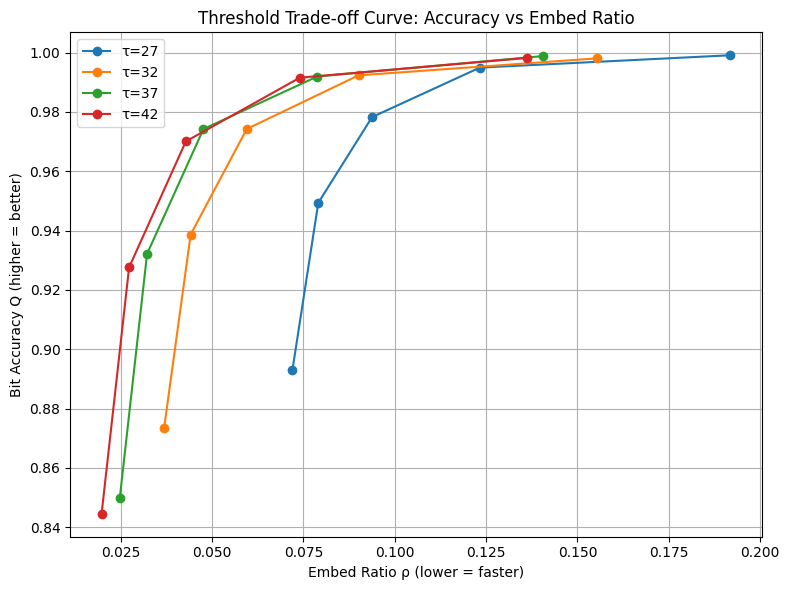

In [8]:
def visualize_threshold_curve(grouped: pd.DataFrame):
    plt.figure(figsize=(8,6))

    for threshold in grouped["threshold"].unique():
        sub = grouped[grouped["threshold"] == threshold]
        plt.plot(sub["embed_ratio"], sub["bit_acc_Identity_0"], marker="o", label=f"τ={threshold}")

    plt.xlabel("Embed Ratio ρ (lower = faster)")
    plt.ylabel("Bit Accuracy Q (higher = better)")
    plt.title("Threshold Trade-off Curve: Accuracy vs Embed Ratio")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

visualize_threshold_curve(content_grouped)

## Quality-Constrained Best Threshold

Choose threshold that gives:

accuracy ≥ threshold (e.g. ≥ 0.99)

minimal n_embed (fastest among those)

This is the industry standard approach for watermarking, video transcoding, denoising thresholds, etc.

In [9]:
# -------------------------------------------------------------------
# 3A. Quality-constrained optimal (threshold, step_size)
# -------------------------------------------------------------------
DEFAULT_QUALITY_TARGET = 0.99

def print_quality_constrained_best_threshold(grouped: pd.DataFrame, quality_target: float = DEFAULT_QUALITY_TARGET):
    valid = grouped[grouped["bit_acc_Identity_0"] >= quality_target]

    if len(valid) == 0:
        print("No configuration meets accuracy target.")
        best_quality_pair = None
    else:
        best_row = valid.loc[valid["n_embed"].idxmin()]
        best_quality_pair = (best_row["threshold"].item(), best_row["step_size"].item())
        print("\nQuality-constrained best (threshold, step_size) =", best_quality_pair)

print_quality_constrained_best_threshold(content_grouped)


Quality-constrained best (threshold, step_size) = (42.0, 16.0)


## Method 2 — Knee/Elbow Best Threshold

In [10]:
# -------------------------------------------------------------------
# 3B. Knee-point / elbow for (threshold, step_size)
# -------------------------------------------------------------------

def knee_elbow_best_threshold(grouped: pd.DataFrame):
    # Min-max normalize
    acc_n = (grouped["bit_acc_Identity_0"] - grouped["bit_acc_Identity_0"].min()) / (grouped["bit_acc_Identity_0"].max() - grouped["bit_acc_Identity_0"].min())
    rho_n = (grouped["embed_time"] - grouped["embed_time"].min()) / (grouped["embed_time"].max() - grouped["embed_time"].min())

    # Define diagonal line between best speed and best quality
    p1 = np.array([rho_n.min(), acc_n.max()])
    p2 = np.array([rho_n.max(), acc_n.min()])

    def point_line_dist(p, a, b):
        # pure 2D cross-product area
        cross = abs((b[0] - a[0]) * (a[1] - p[1]) -
                    (b[1] - a[1]) * (a[0] - p[0]))
        return cross / np.linalg.norm(b - a)

    # Compute distance of each (τ, s)
    distances = [
        point_line_dist(np.array([rho_n.iloc[i], acc_n.iloc[i]]), p1, p2)
        for i in range(len(grouped))
    ]

    idx = np.argmax(distances)
    knee_row = grouped.iloc[idx]
    best_knee_pair = (knee_row["threshold"].item(), knee_row["step_size"].item())

    print("\nKnee-point best (threshold, step_size) =", best_knee_pair)

knee_elbow_best_threshold(content_grouped)


Knee-point best (threshold, step_size) = (27.0, 8.0)


## Method 3 — Pareto Frontier (Speed vs Accuracy)

In [11]:
# -------------------------------------------------------------------
# 3C. Pareto frontier for (threshold, step_size)
# -------------------------------------------------------------------

def pareto_frontier(grouped: pd.DataFrame):
    pareto = []
    for i, r in grouped.iterrows():
        dominated = False
        for j, s in grouped.iterrows():
            if i == j:
                continue
            # s dominates r if:
            #    s is faster (embed_time <= r.embed_time)
            #    s is more accurate (acc >= r.acc)
            #    at least one strict improvement
            if (
                (s["embed_time"] <= r["embed_time"]) and
                (s["bit_acc_Identity_0"] >= r["bit_acc_Identity_0"]) and
                ((s["embed_time"] < r["embed_time"]) or (s["bit_acc_Identity_0"] > r["bit_acc_Identity_0"]))
            ):
                dominated = True
                break
        if not dominated:
            pareto.append(r)

    pareto_df = pd.DataFrame(pareto).sort_values(["threshold", "step_size"])
    print("\nPareto-optimal (threshold, step_size) pairs:")
    print(pareto_df[["threshold", "step_size", "embed_time", "bit_acc_Identity_0"]])
    return pareto_df

pareto_frontier(content_grouped)


Pareto-optimal (threshold, step_size) pairs:
    threshold  step_size  embed_time  bit_acc_Identity_0
0        27.0        8.0  113.106360            0.999089
10       37.0        8.0   53.308897            0.998828
11       37.0       16.0   52.950627            0.991927


,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
0,27.0,8.0,0.191876,0.999089,113.106360,9.846959e-75,76.511451,253.864217,2.515805,80.133333
10,37.0,8.0,0.140623,0.998828,53.308897,1.931681e-74,76.360880,253.301748,0.430442,58.800000
11,37.0,16.0,0.078764,0.991927,52.950627,8.725696e-62,73.068882,241.646933,0.444737,33.433333


## Hash Detector

In [12]:
# -------------------------------------------------------------------
# HashDetector
# -------------------------------------------------------------------

hash_paths = {
    0.3: "output/step_size_eval/HashDetector/threshold_0.3/combined_metrics.csv",
    0.35: "output/step_size_eval/HashDetector/threshold_0.35/combined_metrics.csv",
    0.395: "output/step_size_eval/HashDetector/threshold_0.395/combined_metrics.csv",
    0.45: "output/step_size_eval/HashDetector/threshold_0.45/combined_metrics.csv",
}

hash_results_df = compute_metrics_per_threshold(hash_paths)
hash_results_df

,threshold,embed_ratio,acc,embed_time,pvalue,log_pvalue,capacity,extract_time
0,0.300,0.067064,0.948099,99.034007,1.054373e-11,60.625648,199.529894,0.941910
1,0.350,0.058698,0.947240,100.670260,1.111816e-09,60.093821,197.704884,0.752477
2,0.395,0.054650,0.944557,100.857209,7.516573e-11,59.295476,194.960703,0.800586
3,0.450,0.056815,0.947240,79.202718,4.277949e-07,60.234122,198.071778,0.697546


In [13]:
hash_grouped = group_by_threshold_stepsize(hash_paths)

hash_grouped

,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
0,0.300,8,0.142107,0.997526,93.348943,3.897672e-66,75.744526,251.174168,1.496229,63.900000
1,0.300,16,0.080862,0.985286,100.195869,1.092831e-46,70.366838,232.225980,0.742281,36.433333
2,0.300,32,0.050087,0.959635,99.784677,7.763415e-25,61.894919,203.502829,0.963991,22.666667
3,0.300,64,0.034832,0.928646,100.149500,9.231077e-23,53.463040,175.079138,0.709974,15.866667
4,0.300,128,0.027432,0.869401,101.691046,5.271867e-11,41.658916,135.667353,0.797078,12.566667
5,0.350,8,0.134568,0.995964,101.000242,7.263989e-58,75.039074,248.675758,0.764530,60.500000
6,0.350,16,0.072505,0.985156,99.239347,1.178980e-51,70.304056,232.076054,0.751902,32.666667
7,0.350,32,0.041549,0.964453,100.259756,1.203539e-33,63.126939,207.641257,0.683655,18.800000
8,0.350,64,0.026195,0.920833,101.947878,2.680261e-18,51.436988,168.307042,0.694135,11.933333
9,0.350,128,0.018673,0.869792,100.904075,5.559080e-09,40.562050,131.824309,0.868164,8.566667


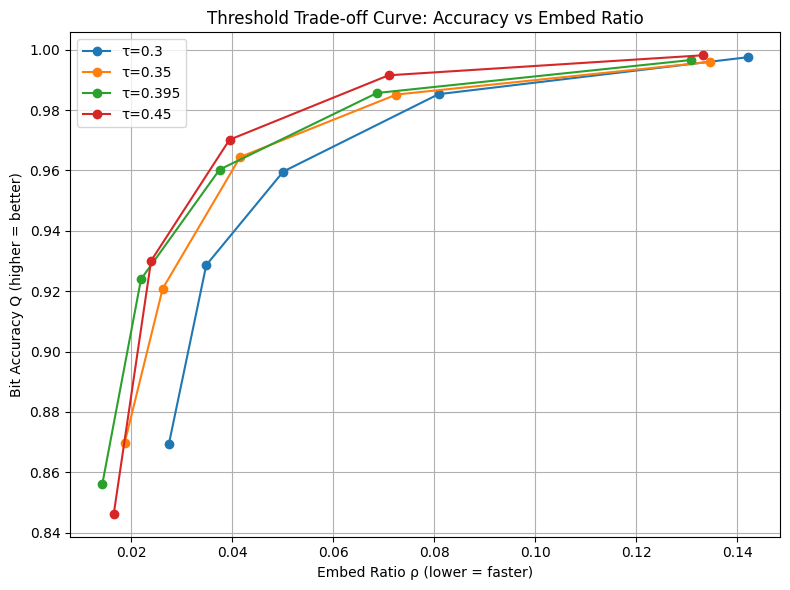

In [14]:
visualize_threshold_curve(hash_grouped)

In [15]:
print_quality_constrained_best_threshold(hash_grouped)


Quality-constrained best (threshold, step_size) = (0.45, 16.0)


In [16]:
knee_elbow_best_threshold(hash_grouped)


Knee-point best (threshold, step_size) = (0.45, 128.0)


In [17]:
pareto_frontier(hash_grouped)


Pareto-optimal (threshold, step_size) pairs:
    threshold  step_size  embed_time  bit_acc_Identity_0
15       0.45        8.0   79.278964            0.998177
16       0.45       16.0   78.262439            0.991536


,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
15,0.45,8.0,0.133272,0.998177,79.278964,3.897620e-66,76.089748,252.412823,0.675195,54.300000
16,0.45,16.0,0.070954,0.991536,78.262439,1.878811e-60,72.732845,240.332461,0.567223,28.666667


## Histogram Detector

In [25]:
# -------------------------------------------------------------------
# HistogramDetector
# -------------------------------------------------------------------

hist_paths = {
    0.01: "output/step_size_eval/HistogramDetector/threshold_0.01/combined_metrics.csv",
    0.05: "output/step_size_eval/HistogramDetector/threshold_0.05/combined_metrics.csv",
    0.1: "output/step_size_eval/HistogramDetector/threshold_0.1/combined_metrics.csv",
    0.15: "output/step_size_eval/HistogramDetector/threshold_0.15/combined_metrics.csv",
}

hist_results_df = compute_metrics_per_threshold(hist_paths)
hist_results_df

,threshold,embed_ratio,acc,embed_time,pvalue,log_pvalue,capacity,extract_time
0,0.01,0.164768,0.959896,52.229998,1.317094e-04,64.445041,212.583842,1.491915
1,0.05,0.079453,0.952292,51.109349,6.308957e-08,61.752741,203.297274,1.400235
2,0.10,0.067181,0.950495,51.098976,7.112580e-06,61.318088,201.829657,1.389106
3,0.15,0.062469,0.947865,51.574570,4.277949e-07,60.425743,198.734943,1.469372


In [26]:
hist_grouped = group_by_threshold_stepsize(hist_paths)

hist_grouped

,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
0,0.01,8,0.255919,0.998828,47.907560,1.931681e-74,76.360880,253.301748,1.846494,114.300000
1,0.01,16,0.188969,0.995182,49.391922,1.257312e-64,74.536966,246.758671,1.413285,88.433333
2,0.01,32,0.151635,0.979557,53.265300,1.199770e-46,68.308088,225.353561,1.420970,74.200000
3,0.01,64,0.120291,0.948047,55.302511,1.068650e-26,58.315319,191.437718,1.392088,61.966667
4,0.01,128,0.107025,0.877865,55.282695,6.585470e-04,44.703953,146.067513,1.386738,56.033333
5,0.05,8,0.158245,0.997917,43.208709,1.087287e-67,75.940994,251.886748,1.430005,67.600000
6,0.05,16,0.094644,0.991536,49.767269,3.853106e-59,72.776650,240.493403,1.422701,41.900000
7,0.05,32,0.061989,0.972917,53.570851,1.989878e-44,65.485040,215.488434,1.397580,28.666667
8,0.05,64,0.045312,0.935547,54.342414,3.861472e-24,54.693528,179.095147,1.382051,21.900000
9,0.05,128,0.037075,0.863542,54.657505,3.154478e-07,39.867491,129.522637,1.368837,18.433333


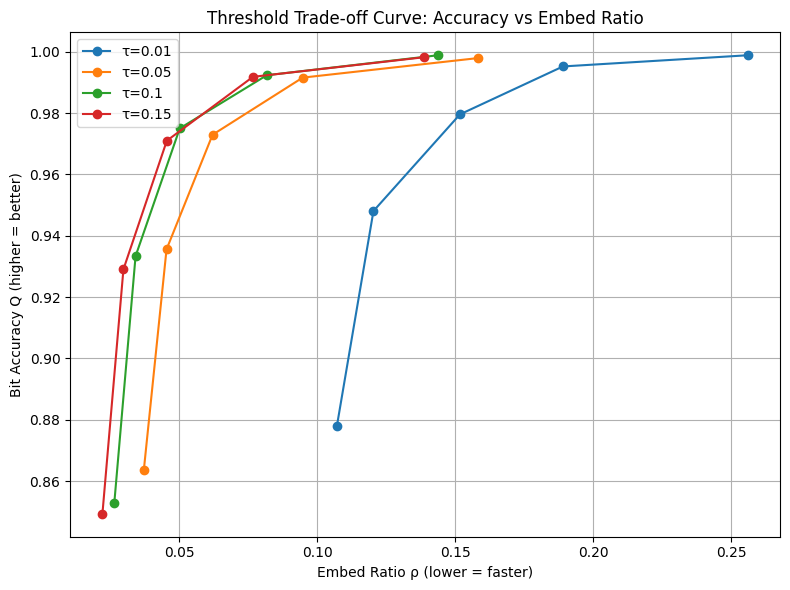

In [28]:
visualize_threshold_curve(hist_grouped)

In [29]:
print_quality_constrained_best_threshold(hist_grouped)


Quality-constrained best (threshold, step_size) = (0.15, 16.0)


In [30]:
knee_elbow_best_threshold(hist_grouped)


Knee-point best (threshold, step_size) = (0.01, 32.0)


In [31]:
pareto_frontier(hist_grouped)


Pareto-optimal (threshold, step_size) pairs:
    threshold  step_size  embed_time  bit_acc_Identity_0
10        0.1        8.0    42.93212            0.998828


,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
10,0.1,8.0,0.143665,0.998828,42.93212,1.931681e-74,76.36088,253.301748,1.379098,60.633333


## LPIPS Detector

In [32]:
lpips_paths = {
    0.05: "output/step_size_eval/LpipsDetector/threshold_0.05/combined_metrics.csv",
    0.075: "output/step_size_eval/LpipsDetector/threshold_0.075/combined_metrics.csv",
    0.1: "output/step_size_eval/LpipsDetector/threshold_0.1/combined_metrics.csv",
    0.125: "output/step_size_eval/LpipsDetector/threshold_0.125/combined_metrics.csv",
}

lpips_results_df = compute_metrics_per_threshold(lpips_paths)
lpips_results_df

,threshold,embed_ratio,acc,embed_time,pvalue,log_pvalue,capacity,extract_time
0,0.050,0.352693,0.996042,47.748034,9.897658e-42,75.295334,249.700417,1.204395
1,0.075,0.238892,0.979479,49.411825,1.871053e-06,70.345729,232.730887,1.136014
2,0.100,0.174107,0.975469,51.831168,2.750518e-10,68.729312,227.159895,1.282719
3,0.125,0.139478,0.971302,48.925941,1.847071e-13,67.072905,221.412313,1.118075


In [33]:
lpips_grouped = group_by_threshold_stepsize(lpips_paths)

lpips_grouped

,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
0,0.050,8,0.405164,0.999609,40.765772,2.297221e-76,76.822686,255.056012,1.540976,171.733333
1,0.050,16,0.362390,0.999479,44.243153,8.050930e-73,76.768461,254.900412,1.114621,154.533333
2,0.050,32,0.341053,0.998437,50.008474,5.194700e-71,76.192337,252.784625,1.126614,145.966667
3,0.050,64,0.329959,0.995703,51.813604,1.878685e-60,74.887295,248.150044,1.119431,141.400000
4,0.050,128,0.324897,0.986979,51.909166,4.948829e-41,71.805893,237.610993,1.120335,139.300000
5,0.075,8,0.300608,0.998437,43.738382,1.022649e-70,76.212574,252.893363,1.168904,127.933333
6,0.075,16,0.250378,0.996745,47.177238,1.218311e-64,75.336801,249.662298,1.125419,107.566667
7,0.075,32,0.224879,0.987500,51.063444,2.761226e-39,71.758553,237.315305,1.105340,97.333333
8,0.075,64,0.212137,0.971484,52.662837,3.361496e-22,67.470018,222.865603,1.149568,92.166667
9,0.075,128,0.206458,0.943229,52.417225,9.355263e-06,60.950699,200.917865,1.130838,89.733333


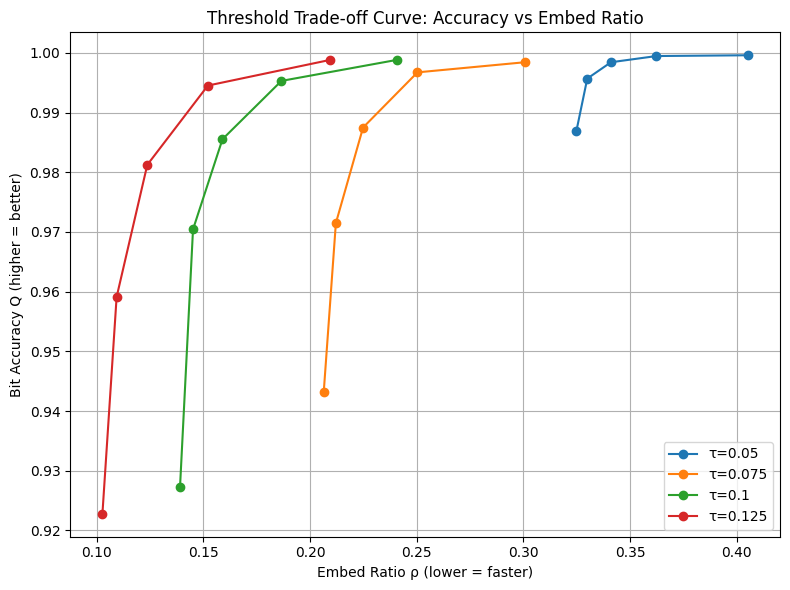

In [34]:
visualize_threshold_curve(lpips_grouped)

In [35]:
print_quality_constrained_best_threshold(lpips_grouped)


Quality-constrained best (threshold, step_size) = (0.125, 16.0)


In [36]:
knee_elbow_best_threshold(lpips_grouped)


Knee-point best (threshold, step_size) = (0.05, 64.0)


In [37]:
pareto_frontier(lpips_grouped)


Pareto-optimal (threshold, step_size) pairs:
   threshold  step_size  embed_time  bit_acc_Identity_0
0       0.05        8.0   40.765772            0.999609


,threshold,step_size,embed_ratio,bit_acc_Identity_0,embed_time,pvalue_Identity_0,log_pvalue_Identity_0,capacity_Identity_0,extract_time,n_embed
0,0.05,8.0,0.405164,0.999609,40.765772,2.297221e-76,76.822686,255.056012,1.540976,171.733333
